# Actividad 6 (10 %): Documentación del código

**Universidad de Antioquia** · Computación Cuántica · Práctica de Laboratorio No. 3: Algoritmo de Grover  
**Autores:** Carlos Andres Duran Paredes y Juan David Zapata Londoño

Versión documentada del algoritmo de Grover modular (actividades 3 y 4). Para cada parte del circuito se explica **qué hace** y **por qué funciona**:

| Parte | Justificación |
|---|---|
| Inicialización | Prepara la superposición uniforme $\lvert\psi\rangle = \lvert s\rangle$ |
| Oracle | Cambia la fase del estado marcado: $U_w = I - 2\lvert w\rangle\langle w\rvert$ |
| Difusor | Inversión sobre la media: $2\lvert\psi\rangle\langle\psi\rvert - I$ |
| Iteraciones | Cada par Oracle·Difusor rota el estado un ángulo $2\theta$ hacia $\lvert w\rangle$; $k \approx \frac{\pi}{4}\sqrt{N/M}$ |

Después de cada demostración hay una celda que la **comprueba numéricamente** con `Operator` y `Statevector`.

**Notación.** $n$ qubits, $N = 2^n$ estados, $\lvert w\rangle$ es el estado marcado y
$\lvert s\rangle = H^{\otimes n}\lvert 0\rangle^{\otimes n} = \frac{1}{\sqrt N}\sum_{x=0}^{N-1}\lvert x\rangle$.
El enunciado llama $\lvert\psi\rangle$ a este estado; aquí $\lvert\psi\rangle \equiv \lvert s\rangle$.
Orden de Qiskit (*little-endian*): en `'101'` el dígito de la derecha es $q_0$.

In [ ]:
!pip install qiskit qiskit-aer

In [ ]:
!pip install -q pylatexenc

In [3]:
# Librerías
from qiskit import QuantumCircuit, transpile          # construcción y transpilación de circuitos
from qiskit.quantum_info import Statevector, Operator # vector de estado y matriz unitaria exactos
from qiskit.visualization import plot_histogram       # histograma de conteos
from qiskit_aer import AerSimulator                   # simulador con muestreo (disparos)
import numpy as np

In [4]:
# Parámetros del problema
n = 3               # número de qubits -> N = 2^n = 8 elementos en la "lista"
MarkState = '101'   # estado buscado |w> (MSB → LSB): q2 = 1, q1 = 0, q0 = 1
N = 2**n

# Vectores de referencia para las comprobaciones numéricas
s = np.ones(N) / np.sqrt(N)                 # |s> = superposición uniforme
w = np.zeros(N); w[int(MarkState, 2)] = 1   # |w> = estado marcado (vector de la base)

## 1. Bloque de Inicialización

Los qubits empiezan en $\lvert 0\cdots0\rangle$. Una $H$ en cada qubit produce la superposición uniforme:

$$H^{\otimes n}\lvert 0\cdots0\rangle = \bigotimes_{i=0}^{n-1}\frac{\lvert 0\rangle+\lvert 1\rangle}{\sqrt2} = \frac{1}{\sqrt N}\sum_{x=0}^{N-1}\lvert x\rangle = \lvert s\rangle .$$

Todas las amplitudes valen $1/\sqrt N$, así que, antes de buscar, cada elemento tiene probabilidad $1/N$. Es el punto de partida "sin información":
el algoritmo no sabe dónde está $\lvert w\rangle$ y empieza con todos los candidatos a la vez.

¿H^n |0> = |s>? True


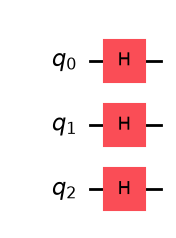

In [5]:
def Inicializacion(n):
    """
    Bloque 1 - Inicialización.
    Aplica H a los n qubits: |0...0>  ->  |s> = (1/sqrt(N)) * suma de todos los |x>.
    Cada estado de la base queda con amplitud 1/sqrt(N) y probabilidad 1/N.
    """
    bloque = QuantumCircuit(n, name='Inicialización')
    bloque.h(range(n))     # H en cada qubit: |0> -> (|0> + |1>)/sqrt(2)
    return bloque

# Comprobación: el bloque produce |s>
print('¿H^n |0> = |s>?', np.allclose(Statevector(Inicializacion(n)).data, s))
Inicializacion(n).draw('mpl')

## 2. Bloque Oracle: cómo cambia la fase del estado marcado

**Función dentro del algoritmo.** El oracle es la única parte que "conoce" la respuesta. No la revela directamente: solo le pone un signo $-1$ al
estado buscado. Debe cumplir

$$U_w\lvert x\rangle = (-1)^{f(x)}\lvert x\rangle, \qquad f(x) = \begin{cases}1 & x = w\\ 0 & x\neq w\end{cases}
\qquad\Longleftrightarrow\qquad U_w = I - 2\lvert w\rangle\langle w\rvert .$$

Se construye en tres pasos.

**Paso 1: llevar $\lvert w\rangle$ a $\lvert 1\cdots1\rangle$.** Se aplica $X$ a cada qubit cuyo dígito en $w$ es `0`. Llamemos $X_{\bar w}$ a ese producto de $X$.
Como $X\lvert 0\rangle = \lvert 1\rangle$, se cumple $X_{\bar w}\lvert w\rangle = \lvert 1\cdots1\rangle$. $X_{\bar w}$ solo permuta los estados de la base
(es una biyección), así que ningún otro estado llega a $\lvert 1\cdots1\rangle$. Además $X_{\bar w}^2 = I$ y $X_{\bar w}^\dagger = X_{\bar w}$.

**Paso 2: Z multicontrolada sobre $\lvert 1\cdots1\rangle$.** Se aplica $H$ al último qubit, una $X$ multicontrolada (MCX) con los demás qubits
como controles, y otra $H$. Como $HXH = Z$:

$$H_{n-1}\,\mathrm{MCX}\,H_{n-1} = \mathrm{MCZ}.$$

La MCZ aplica $Z$ al último qubit solo si todos los controles valen 1. $Z\lvert 1\rangle = -\lvert 1\rangle$ y $Z\lvert 0\rangle = \lvert 0\rangle$, así que el único estado
que cambia es $\lvert 1\cdots1\rangle$, que adquiere un signo $-1$:

$$\mathrm{MCZ} = I - 2\lvert 1\cdots1\rangle\langle 1\cdots1\rvert .$$

**Paso 3: deshacer el paso 1 (*uncompute*).** Se repiten las mismas $X$:

$$U_w = X_{\bar w}\,\mathrm{MCZ}\,X_{\bar w} = X_{\bar w}\big(I - 2\lvert 1\cdots1\rangle\langle 1\cdots1\rvert\big)X_{\bar w}
= I - 2\,\big(X_{\bar w}\lvert 1\cdots1\rangle\big)\big(X_{\bar w}\lvert 1\cdots1\rangle\big)^\dagger = I - 2\lvert w\rangle\langle w\rvert .$$

**Efecto sobre la superposición.** Aplicado a $\lvert s\rangle$:

$$U_w\lvert s\rangle = \frac{1}{\sqrt N}\Big(\sum_{x\neq w}\lvert x\rangle - \lvert w\rangle\Big).$$

Solo la amplitud de $\lvert w\rangle$ cambia de signo. Es una **fase relativa**: las probabilidades $|{\pm}1/\sqrt N|^2$ no cambian, así que medir en este punto
no revela nada. El signo es la "marca" que el difusor convierte después en amplitud. A diferencia del tutorial de IBM, no se usa un qubit auxiliar en
$\lvert -\rangle$: la fase se aplica directamente sobre los qubits de datos.

**Varios estados marcados.** Si se marcan $M$ estados distintos, el bloque repite los tres pasos para cada uno. Los factores $I - 2\lvert w\rangle\langle w\rvert$
son diagonales y conmutan, y como $\langle w\vert w'\rangle = 0$ para $w\neq w'$, su producto es $I - 2\sum_w \lvert w\rangle\langle w\rvert$: cada estado marcado recibe su propio $-1$.

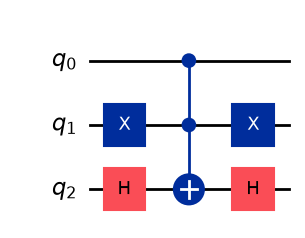

In [6]:
def lista_marcados(MarkState):
    # Acepta un estado ('101') o una lista de estados (['011', '110'])
    return [MarkState] if isinstance(MarkState, str) else list(MarkState)


def Oracle(MarkState):
    """
    Bloque 2 - Oracle de fase:  U_w = I - 2|w><w|  (con varios estados: I - 2 Σ_w |w><w|).
    MarkState: cadena con el estado marcado w, por ejemplo '101' (MSB → LSB), o lista de cadenas.

    Cómo cambia la fase de |w>:
      Paso 1. X en los qubits donde w tiene un 0  ->  |w> se convierte en |1...1>.
      Paso 2. Z multicontrolada (H · MCX · H en el último qubit). Como HXH = Z,
              solo |1...1> recibe el signo -1:  MCZ = I - 2|1...1><1...1|.
      Paso 3. Se deshacen las X del paso 1  ->  el signo -1 queda sobre |w>.
    Resultado: U_w|w> = -|w> y U_w|x> = |x> para x != w (solo cambia una fase relativa).
    """
    marcados = lista_marcados(MarkState)
    n = len(marcados[0])
    bloque = QuantumCircuit(n, name='Oracle')

    for w in marcados:
        # Paso 1: X donde el bit es 0. reversed() porque en Qiskit el último dígito de la cadena es q0
        for i, bit in enumerate(reversed(w)):
            if bit == '0':
                bloque.x(i)

        # Paso 2: Z multicontrolada = H · MCX · H sobre el último qubit (controles: q0 ... q_{n-2})
        bloque.h(n - 1)
        bloque.mcx(list(range(n - 1)), n - 1)
        bloque.h(n - 1)

        # Paso 3: uncompute, se repiten las mismas X para volver a la base original
        for i, bit in enumerate(reversed(w)):
            if bit == '0':
                bloque.x(i)

    return bloque

Oracle(MarkState).draw('mpl')

In [7]:
# Comprobación numérica del oracle
U_w = Operator(Oracle(MarkState)).data
print('¿U_w = I - 2|w><w| ?', np.allclose(U_w, np.eye(N) - 2 * np.outer(w, w)))
print('Diagonal de U_w:', np.round(np.diag(U_w).real).astype(int))

# Efecto sobre |s>: solo la amplitud de |w> cambia de signo; las probabilidades no cambian
despues_oracle = U_w @ s
print('Amplitudes antes  :', np.round(s, 4))
print('Amplitudes después:', np.round(despues_oracle.real, 4))
print('¿Mismas probabilidades?', np.allclose(np.abs(s)**2, np.abs(despues_oracle)**2))

# Dos estados marcados: I - 2(|w1><w1| + |w2><w2|)
w1, w2 = np.zeros(N), np.zeros(N); w1[int('011', 2)] = 1; w2[int('110', 2)] = 1
print("¿Oracle(['011','110']) = I - 2(|w1><w1| + |w2><w2|) ?",
      np.allclose(Operator(Oracle(['011', '110'])).data, np.eye(N) - 2 * (np.outer(w1, w1) + np.outer(w2, w2))))

¿U_w = I - 2|w><w| ? True
Diagonal de U_w: [ 1  1  1  1  1 -1  1  1]
Amplitudes antes  : [0.3536 0.3536 0.3536 0.3536 0.3536 0.3536 0.3536 0.3536]
Amplitudes después: [ 0.3536  0.3536  0.3536  0.3536  0.3536 -0.3536  0.3536  0.3536]
¿Mismas probabilidades? True
¿Oracle(['011','110']) = I - 2(|w1><w1| + |w2><w2|) ? True


## 3. Bloque Difusor: demostración de la inversión sobre la media

**Función dentro del algoritmo.** El oracle solo cambia un signo, que no se ve al medir. El difusor convierte esa diferencia de signo en una diferencia de
**magnitud**: aumenta la amplitud del estado marcado y reduce las demás (amplificación de amplitud).

El difusor se construye como $H^{\otimes n}\,X^{\otimes n}\,\mathrm{MCZ}\,X^{\otimes n}\,H^{\otimes n}$.

**Paso 1: reflexión sobre $\lvert 0\cdots0\rangle$.** Por el mismo argumento del oracle (ahora con $X$ en **todos** los qubits, que llevan
$\lvert 0\cdots0\rangle$ a $\lvert 1\cdots1\rangle$):

$$X^{\otimes n}\,\mathrm{MCZ}\,X^{\otimes n} = I - 2\lvert 0\rangle\langle 0\rvert, \qquad \lvert 0\rangle \equiv \lvert 0\cdots0\rangle .$$

**Paso 2: cambio de base con $H^{\otimes n}$.** $H$ es hermítica y $H^2 = I$, así que $H^{\otimes n}H^{\otimes n} = I$ y
$\langle 0\rvert H^{\otimes n} = \big(H^{\otimes n}\lvert 0\rangle\big)^\dagger = \langle s\rvert$. Entonces

$$D_c = H^{\otimes n}\big(I - 2\lvert 0\rangle\langle 0\rvert\big)H^{\otimes n} = H^{\otimes n}H^{\otimes n} - 2\,H^{\otimes n}\lvert 0\rangle\langle 0\rvert H^{\otimes n}
= I - 2\lvert s\rangle\langle s\rvert = -\big(2\lvert s\rangle\langle s\rvert - I\big).$$

El circuito implementa $D = 2\lvert\psi\rangle\langle\psi\rvert - I$ multiplicado por $-1$. Un factor global $-1$ es una **fase global**: no cambia ninguna
probabilidad ni ninguna medición, así que $D_c$ y $D$ son físicamente el mismo operador.

**Paso 3: por qué $2\lvert s\rangle\langle s\rvert - I$ es una inversión sobre la media.** Sea un estado cualquiera $\lvert\varphi\rangle = \sum_x a_x\lvert x\rangle$
y sea $\langle a\rangle = \frac1N\sum_x a_x$ la media de sus amplitudes. Primero,

$$\langle s\vert\varphi\rangle = \frac{1}{\sqrt N}\sum_x a_x = \sqrt N\,\langle a\rangle
\quad\Longrightarrow\quad
2\lvert s\rangle\langle s\vert\varphi\rangle = 2\sqrt N\,\langle a\rangle\cdot\frac{1}{\sqrt N}\sum_x\lvert x\rangle = \sum_x 2\langle a\rangle\,\lvert x\rangle .$$

Restando $I\lvert\varphi\rangle = \sum_x a_x\lvert x\rangle$:

$$\boxed{\big(2\lvert s\rangle\langle s\rvert - I\big)\lvert\varphi\rangle = \sum_x\big(2\langle a\rangle - a_x\big)\lvert x\rangle}$$

Cada amplitud se transforma como $a_x \mapsto 2\langle a\rangle - a_x = \langle a\rangle + (\langle a\rangle - a_x)$: queda a la misma distancia de la media,
pero del otro lado. Eso es una **inversión (reflexión) sobre la media**.

**Aplicación a los estados del sistema.** Después del oracle, $a_x = 1/\sqrt N$ para $x\neq w$ y $a_w = -1/\sqrt N$. La media queda un poco por debajo de
$1/\sqrt N$: $\langle a\rangle = \frac{N-2}{N\sqrt N}$. Al reflejar:

- Los no marcados pasan a $2\langle a\rangle - \frac{1}{\sqrt N} = \frac{N-4}{N\sqrt N}$: disminuyen un poco.
- El marcado pasa a $2\langle a\rangle + \frac{1}{\sqrt N} = \frac{3N-4}{N\sqrt N}$: aproximadamente se triplica.

Por ejemplo, con $N=8$: $\langle a\rangle = \frac{6}{8\sqrt8}$, los no marcados quedan en $\frac{4}{8\sqrt8} = \frac{1}{2\sqrt8} \approx 0.1768$ y el marcado en
$\frac{20}{8\sqrt8} = \frac{5}{2\sqrt8} \approx 0.8839$.

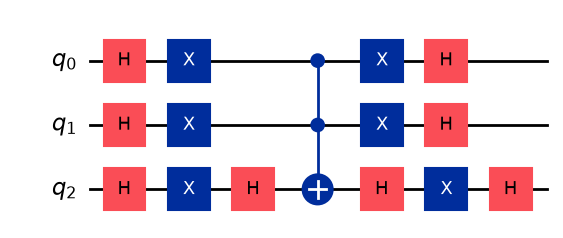

In [8]:
def Difusor(n):
    """
    Bloque 3 - Difusor (inversión sobre la media).
    Implementa  D_c = H^n · (I - 2|0><0|) · H^n = I - 2|s><s| = -(2|s><s| - I).

      X^n · MCZ · X^n      = I - 2|0...0><0...0|   (cambia el signo solo de |0...0>)
      H^n · (...) · H^n    = I - 2|s><s|           (porque H^n|0...0> = |s> y H^n · H^n = I)

    Sobre un estado con amplitudes a_x, 2|s><s| - I produce 2<a> - a_x:
    cada amplitud se refleja respecto a la media <a>. El factor -1 de D_c es una
    fase global y no cambia ninguna probabilidad.
    """
    bloque = QuantumCircuit(n, name='Difusor')

    bloque.h(range(n))                     # H^n: lleva |s> a |0...0>
    bloque.x(range(n))                     # X^n: lleva |0...0> a |1...1>
    bloque.h(n - 1)                        # H · MCX · H = MCZ:
    bloque.mcx(list(range(n - 1)), n - 1)  #   cambia el signo solo de |1...1>
    bloque.h(n - 1)
    bloque.x(range(n))                     # X^n: deshace el cambio |0...0> <-> |1...1>
    bloque.h(range(n))                     # H^n: vuelve a la base computacional

    return bloque

Difusor(n).draw('mpl')

In [9]:
# Comprobación numérica del difusor
D_c = Operator(Difusor(n)).data
D = 2 * np.outer(s, s) - np.eye(N)          # 2|psi><psi| - I del enunciado
print('¿D_c = I - 2|s><s| ?        ', np.allclose(D_c, np.eye(N) - 2 * np.outer(s, s)))
print('¿D_c = -(2|s><s| - I) ?     ', np.allclose(D_c, -D))

# Inversión sobre la media, aplicada al estado que sale del oracle
a = despues_oracle.real
media = a.mean()
print('\nAmplitudes después del oracle:', np.round(a, 4), '  media <a> =', round(media, 4))
print('2<a> - a_x (fórmula)        :', np.round(2 * media - a, 4))
print('D |phi> (matriz)            :', np.round((D @ a).real, 4))
print('¿D|phi> = 2<a> - a_x ?      ', np.allclose(D @ a, 2 * media - a))
print('D_c |phi> (circuito)        :', np.round((D_c @ a).real, 4), ' <- igual, con signo global -1')

¿D_c = I - 2|s><s| ?         True
¿D_c = -(2|s><s| - I) ?      True

Amplitudes después del oracle: [ 0.3536  0.3536  0.3536  0.3536  0.3536 -0.3536  0.3536  0.3536]   media <a> = 0.2652
2<a> - a_x (fórmula)        : [0.1768 0.1768 0.1768 0.1768 0.1768 0.8839 0.1768 0.1768]
D |phi> (matriz)            : [0.1768 0.1768 0.1768 0.1768 0.1768 0.8839 0.1768 0.1768]
¿D|phi> = 2<a> - a_x ?       True
D_c |phi> (circuito)        : [-0.1768 -0.1768 -0.1768 -0.1768 -0.1768 -0.8839 -0.1768 -0.1768]  <- igual, con signo global -1


## 4. Operador de Grover y número de iteraciones

**Por qué hay que repetir Oracle·Difusor.** Una sola iteración aumenta la amplitud del estado marcado, pero en general no la lleva hasta 1
(con $N = 8$ pasa de $0.354$ a $0.884$). Cada repetición la aumenta un poco más, hasta un máximo.

**El estado vive en un plano.** Sea $\lvert w^\perp\rangle$ la superposición uniforme de los estados no marcados. Con $M$ estados marcados y
$\lvert w\rangle$ la superposición uniforme de los marcados:

$$\lvert s\rangle = \sin\theta\,\lvert w\rangle + \cos\theta\,\lvert w^\perp\rangle, \qquad \sin\theta = \sqrt{\frac{M}{N}}\quad(\text{con } M=1:\ \sin\theta = 1/\sqrt N).$$

Oracle y difusor solo combinan $\lvert w\rangle$ y $\lvert w^\perp\rangle$, así que el estado nunca sale de ese plano.

**Cada iteración es una rotación de $2\theta$.**

- El oracle $U_w$ es una reflexión respecto a $\lvert w^\perp\rangle$ (invierte la componente en $\lvert w\rangle$).
- El difusor $2\lvert s\rangle\langle s\rvert - I$ es una reflexión respecto a $\lvert s\rangle$.
- Dos reflexiones respecto a rectas que forman un ángulo $\theta$ equivalen a una rotación de $2\theta$.

Por eso, después de $k$ iteraciones:

$$G^k\lvert s\rangle = \sin\big((2k+1)\theta\big)\lvert w\rangle + \cos\big((2k+1)\theta\big)\lvert w^\perp\rangle,
\qquad P_{\text{éxito}}(k) = \sin^2\big((2k+1)\theta\big).$$

**Número de iteraciones.** La probabilidad es máxima cuando $(2k+1)\theta \approx \frac{\pi}{2}$, es decir $k \approx \frac{\pi}{4\theta} - \frac12$.
Para $M \ll N$, $\theta \approx \sin\theta = \sqrt{M/N}$, y queda

$$k \approx \frac{\pi}{4}\sqrt{\frac{N}{M}} \qquad\big(M = 1:\ k \approx \tfrac{\pi}{4}\sqrt{2^n}\big).$$

$k$ debe ser entero y se toma la parte entera (`floor`): redondear hacia arriba puede pasarse de $\frac{\pi}{2}$. Con $n=2$, $\frac{\pi}{4}\sqrt4 = 1.57$
redondearía a 2 y la probabilidad caería a $1/4$; con `floor` se obtiene $k=1$ y probabilidad 1.

**Qué pasa con demasiadas iteraciones.** Pasado el óptimo, la rotación sigue y aleja el estado de $\lvert w\rangle$: la probabilidad baja. El comportamiento es
periódico en $k$ (la tabla de abajo lo muestra).

In [10]:
def OperadorGrover(qc, MarkState):
    """
    Una iteración de Grover G = Difusor · Oracle sobre el circuito qc.
    Geométricamente: dos reflexiones = rotación de 2*theta hacia los estados marcados.
    """
    n = qc.num_qubits
    qubits = list(range(n))
    qc.append(Oracle(MarkState).to_gate(label='Oracle'), qubits)   # reflexión respecto a |w_perp>
    qc.barrier()
    qc.append(Difusor(n).to_gate(label='Difusor'), qubits)         # reflexión respecto a |s>
    qc.barrier()


def Iteraciones(n, M=1):
    """
    Número de iteraciones de Grover (Oracle · Difusor).
    Cada iteración rota el estado 2*theta, con sin(theta) = sqrt(M/N), N = 2^n.
    El óptimo es (2k+1)*theta ≈ pi/2  ->  k ≈ (pi/4)*sqrt(N/M).
    Se toma la parte entera para no pasarse del ángulo pi/2.
    Casos límite: M fuera de [1, N] -> error;  M >= N/2 -> k = 0 (iterar no mejora).
    """
    N = 2**n
    if not 1 <= M <= N:
        raise ValueError(f'M debe estar entre 1 y N = {N}; se recibió M = {M}')
    if M >= N / 2:
        return 0
    return int(np.floor(np.pi / 4 * np.sqrt(N / M)))

k = Iteraciones(n)
theta = np.arcsin(1 / np.sqrt(N))
print(f'theta = {np.degrees(theta):.2f}°   (π/4)·√N = {np.pi / 4 * np.sqrt(N):.3f}   ->   k = {k}')

theta = 20.70°   (π/4)·√N = 2.221   ->   k = 2


## 5. Circuito completo

`Grover` conecta los bloques en el orden de la Figura 1: Inicialización → (Oracle → Difusor) × k → Medición.

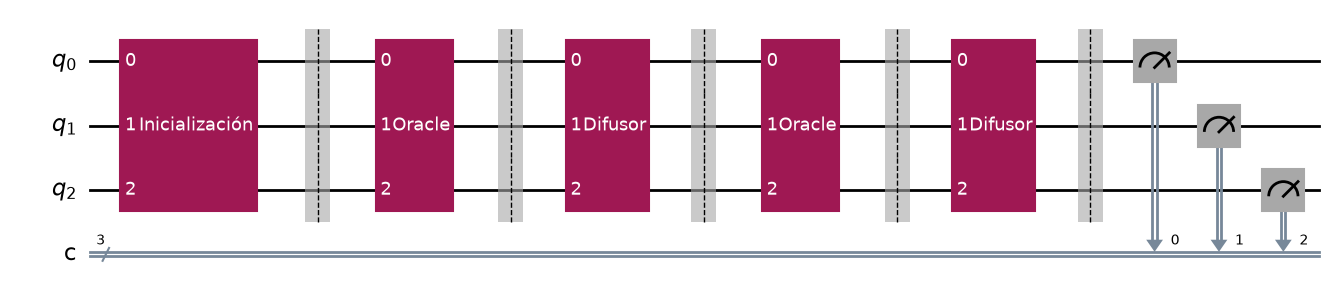

In [11]:
def Medicion(n):
    """Bloque 4 - Medición: cada qubit q_i se mide en el bit clásico c_i."""
    bloque = QuantumCircuit(n, n, name='Medición')
    bloque.measure(range(n), range(n))
    return bloque


def Grover(n, MarkState, num_iteraciones=None, medir=True):
    """
    Ensambla el algoritmo de Grover con los bloques anteriores.
    Si num_iteraciones es None, k se calcula automáticamente con Iteraciones(n, M).
    medir=False deja el circuito sin medición para obtener el Statevector exacto.
    """
    marcados = lista_marcados(MarkState)
    if num_iteraciones is None:
        num_iteraciones = Iteraciones(n, len(marcados))
    qubits = list(range(n))
    qc = QuantumCircuit(n, n) if medir else QuantumCircuit(n)   # qubits en |0...0>

    # Inicialización: |0...0> -> |s>
    qc.append(Inicializacion(n).to_gate(label='Inicialización'), qubits)
    qc.barrier()

    # k iteraciones de Grover: cada una rota el estado 2*theta hacia |w>
    for _ in range(num_iteraciones):
        OperadorGrover(qc, marcados)

    # Medición de los n qubits
    if medir:
        qc.compose(Medicion(n), qubits=qubits, clbits=qubits, inplace=True)
    return qc

grover_circuit = Grover(n, MarkState)
grover_circuit.draw('mpl')

In [12]:
# La probabilidad del estado marcado sigue sin^2((2k+1)·theta): máxima en k = Iteraciones(n)
print(f"{'k':>2} {'sin^2((2k+1)θ)':>15} {'Statevector':>12}")
for k_i in range(0, 6):
    p_sv = Statevector(Grover(n, MarkState, k_i, medir=False)).probabilities()[int(MarkState, 2)]
    marca = '  <- k automático' if k_i == k else ''
    print(f"{k_i:>2} {np.sin((2 * k_i + 1) * theta)**2:>15.4f} {p_sv:>12.4f}{marca}")

 k  sin^2((2k+1)θ)  Statevector
 0          0.1250       0.1250
 1          0.7812       0.7812
 2          0.9453       0.9453  <- k automático
 3          0.3301       0.3301
 4          0.0122       0.0122
 5          0.5480       0.5480


{'010': 6, '000': 8, '011': 8, '111': 8, '110': 8, '100': 6, '001': 10, '101': 970}
Probabilidad de éxito P(101) = 0.9473


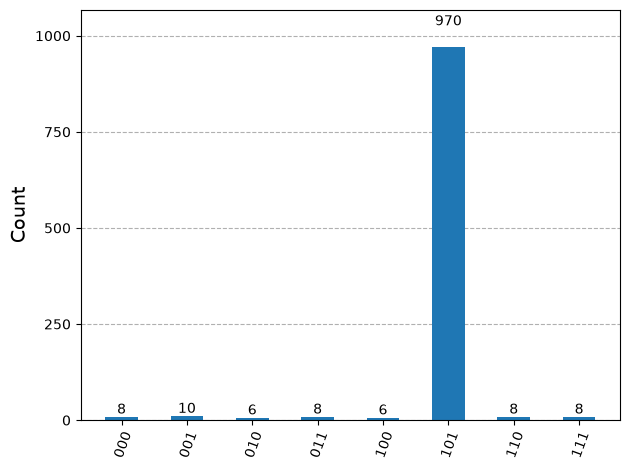

In [13]:
# Simulación con muestreo (1024 disparos)
backend = AerSimulator(seed_simulator=2026)   # semilla fija para poder repetir el resultado
counts = backend.run(transpile(grover_circuit, backend), shots=1024).result().get_counts()
print(counts)
print(f'Probabilidad de éxito P({MarkState}) = {counts.get(MarkState, 0) / 1024:.4f}')
plot_histogram(counts)

In [14]:
from qiskit import __version__ as qiskit_version
from qiskit_aer import __version__ as aer_version
from platform import python_version

print('Qiskit Version:', qiskit_version)
print('Qiskit_Aer Version:', aer_version)
print('Python Version:', python_version())
print('UdeA-Medellin (2026) ©')

Qiskit Version: 2.5.2
Qiskit_Aer Version: 0.18.2
Python Version: 3.13.14
UdeA-Medellin (2026) ©
